# Command resume으로 실행 재개

**이 노트북에서 할 일**

1. 사람의 답이 허용 답 목록에 없으면, 까닭을 알려 주고 같은 자리에서 다시 묻습니다.
2. 조건부 엣지로 다시 묻는 모양과 노드 안 `while True`로 다시 묻는 모양에 같은 답을 넣어 견줍니다.
3. 체크포인터가 없을 때와 스레드 이름이 다를 때, 사람의 답을 넘기면 어떤 오류가 나는지 봅니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
사람의 답은 우리가 셀에 적어 넣는 값(`"maybe"`·`"yes"`·`"approve"`)입니다.
실제 서비스라면 화면에서 사람이 고른 값을 같은 자리에 넣습니다.
매번 같은 값을 내는 우리 노드로, 노드가 시작한 횟수와 체크포인트 수를 셉니다.

체크포인트는 메모리에만 저장하고, 파일은 하나도 쓰지 않습니다.
그래도 01절과 같은 모양으로 빈 임시 폴더를 만들고, 마지막 셀에서 그 폴더가 비어 있는지 봅니다.
읽어 오는 자료 파일은 없습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11, 체크포인터는 langgraph-checkpoint 4.2.0에 들어 있습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**강의와 실습 범위** — 강의 시간에는 2~3절을 읽습니다.
받은 답을 허용 답 목록으로 검사하고, 조건부 엣지로 다시 묻는 자리입니다.
4~6절은 권하지 않는 모양과 견주고 오류 장면을 보는 자리이고, 실습 시간에 실행합니다.
셀 하나만 다시 실행하면 같은 스레드에 답이 더해지고 부른 기록 목록도 늘어, 값이 달라집니다.
처음 값으로 다시 보려면 1절 임시 폴더 셀부터 다시 실행합니다.

실습 폴더 `labs/part6/ch24-human-in-the-loop`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림입니다. 맨 위에 회색 둥근 상자 가상 시작점 START, 초록 상자 허용 답 목록 approve reject, 초록 상자 사람의 답 Command resume으로 넘김이 나란히 놓이고, 셋에서 파란 상자 노드 ask_once로 화살표가 갑니다. 파란 상자에는 interrupt를 한 번 부르고 받은 답을 목록으로 검사가 적혀 있고, 그 아래 회색 마름모 조건 함수 after_answer로 화살표가 갑니다. 마름모에서 나가는 점선 둘 가운데 하나는 오류 칸에 글 있음 이름표 ask_again으로 파란 상자에 되돌아가고, 다른 하나는 오류 칸 빈 글 이름표 END로 맨 아래 회색 둥근 상자 가상 끝점 END에 닿는 그림](attachment:02-1-조건부-엣지로-다시-묻는-그래프.png)

위에서 아래로 읽습니다.
초록 상자는 우리가 넣은 값과 사람의 답이고, 파란 상자는 우리가 적은 노드입니다.
회색 마름모는 노드로 등록하지 않는 조건 함수 `after_answer`이고, 마름모에서 나가는 점선 둘이 조건부 엣지입니다.
오류 칸에 글이 있으면 같은 노드로 되돌아가 다시 묻고, 빈 글이면 끝점으로 갑니다.
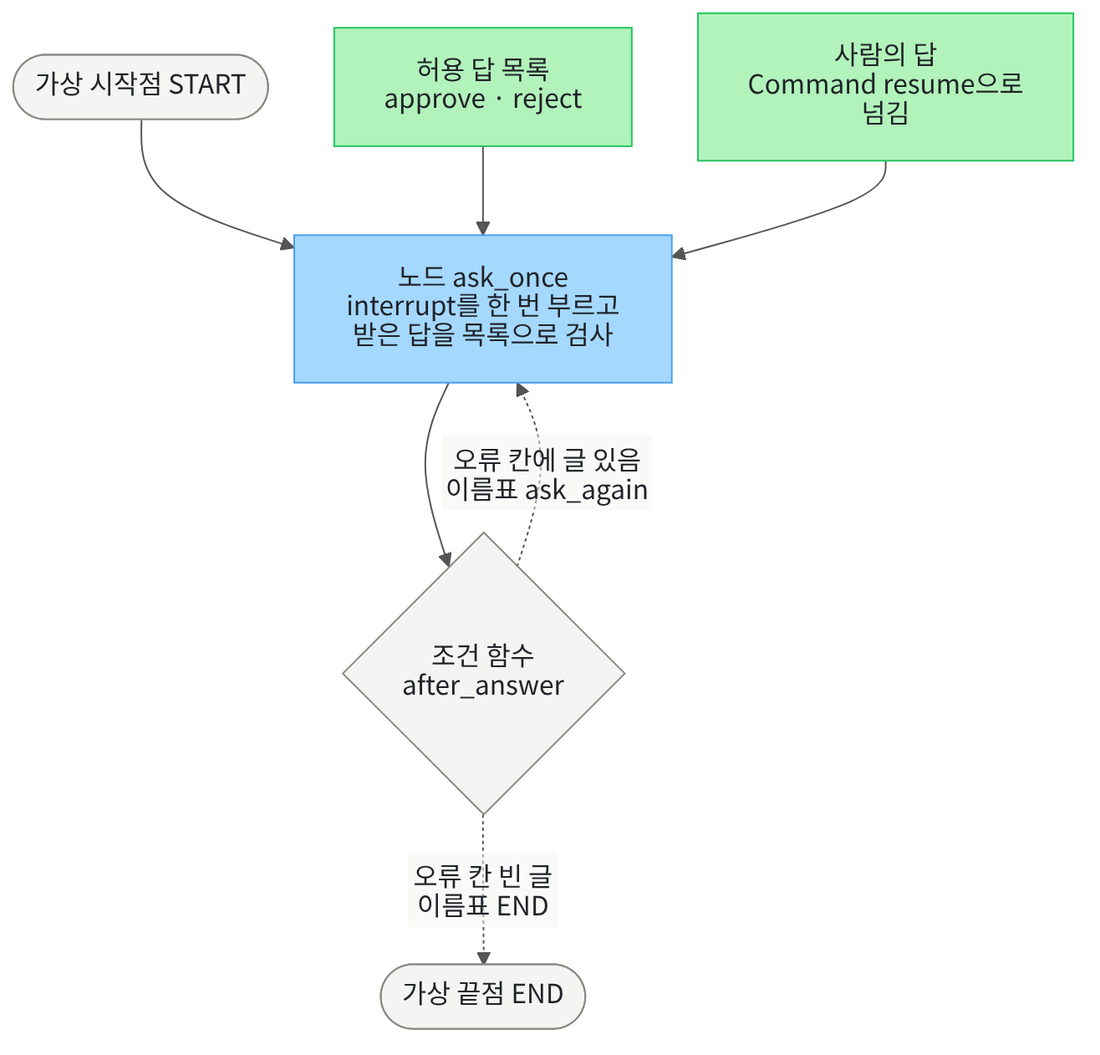

## 1. 준비

01절에서는 사람의 답이 `approve`인지 아닌지만 보았습니다.
실제 화면에서는 사람이 `maybe`처럼 정해 두지 않은 답을 보낼 수도 있습니다.
이 절에서는 받아들일 답을 목록으로 정해 두고, 목록에 없는 답이면 까닭을 알려 준 뒤 다시 묻습니다.
절 제목은 01절의 `Command(resume=…)`로 멈춘 실행을 이어 가는 일을 가리킵니다.
본문에서는 01절처럼 사람의 답으로 이어 가기라고 씁니다.

첫 셀은 01절과 같은 패키지 둘을 설치하고, 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint==4.2.0"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint:", version("langgraph-checkpoint"))

Note: you may need to restart the kernel to use updated packages.


langgraph: 1.2.11
langgraph-checkpoint: 4.2.0


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint: 4.2.0`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01절, 체크포인터 `InMemorySaver`는 Ch 23 01절과 같습니다.
함수 `interrupt`와 객체 `Command`는 01절에서 가져온 이름 그대로입니다.
이 절은 파일을 쓰지 않아, 도구 파일 `approval_tools.py`에서는 아무것도 가져오지 않습니다.

In [2]:
# 그래프 이름(Ch 13 01절)·체크포인터(Ch 23 01절)와, 01절에서 쓴 멈춤 표시 이름 둘을 가져옵니다
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
# interrupt는 노드를 멈추는 함수, Command는 멈춘 그래프에 사람의 답을 넘길 때 쓰는 객체입니다(01절)
from langgraph.types import Command, interrupt

print("langgraph.graph에서 가져온 이름:", "StateGraph, START, END")
print("langgraph.types에서 가져온 이름:", "Command, interrupt")

langgraph.graph에서 가져온 이름: StateGraph, START, END
langgraph.types에서 가져온 이름: Command, interrupt


**결과 읽기** — 출력 줄 `langgraph.types에서 가져온 이름: Command, interrupt`가 보입니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절은 파일을 쓰지 않지만, 마지막 셀에서 이 폴더가 그대로 비어 있는지 봅니다.
폴더 위치는 컴퓨터마다 달라 출력하지 않고, 폴더 이름의 앞머리만 확인합니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 23 01절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch24-02-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch24-02-이 들어 있는가:", "ch24-02-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch24-02-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch24-02-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 허용 답 목록과 질문 값

허용 답 목록은 사람의 답으로 받아들일 값만 적어 둔 목록입니다.
01절의 도미노 줄로 말하면, 빈자리에 맞는 도미노의 모양을 정해 두는 것과 같습니다.
이 절 코드에서는 목록 `allowed_answers`이고, 받은 답이 목록에 있는지 `in`으로 검사합니다.
Ch 16 01절·Ch 18 02절의 허용 목록과 같은 뜻이고, 여기서는 사람의 답에 씁니다.

다음 셀은 목록을 만들고, 목록에 있는 답과 없는 답을 하나씩 검사해 봅니다.

In [4]:
# 사람의 답으로 받아들일 값 둘을 허용 답 목록에 적고, 답 둘을 검사해 봅니다
allowed_answers = ["approve", "reject"]
print("허용 답 목록:", allowed_answers)
# in은 목록에 같은 값이 있으면 True, 없으면 False를 내놓습니다
print("approve가 목록에 있는가:", "approve" in allowed_answers)
print("maybe가 목록에 있는가:", "maybe" in allowed_answers)

허용 답 목록: ['approve', 'reject']
approve가 목록에 있는가: True
maybe가 목록에 있는가: False


**결과 읽기** — 출력 줄 `허용 답 목록: ['approve', 'reject']`입니다.
출력 줄 `approve가 목록에 있는가: True`와 `maybe가 목록에 있는가: False`가 보입니다.
이 절의 노드는 받은 답을 이 목록으로 검사합니다.

다음 셀은 이 절의 상태 형식을 만듭니다.
칸 `order_key`는 주문 키, 칸 `answer`는 받아들인 사람의 답입니다.
칸 `error`는 바로 앞 답을 받아들이지 않은 까닭을 적는 글 칸이고, 빈 글이면 까닭이 없다는 뜻입니다.
세 칸 모두 규칙을 적지 않아, 새 값이 오면 덮어씁니다.
01절의 `ApprovalState`와 칸이 달라, 이름도 새로 붙였습니다.

In [5]:
# 주문 키·사람의 답·오류 글 칸을 둔 상태 형식을 만듭니다(Ch 13 01절 모양, 세 칸 모두 규칙 없음)
class ReviewState(TypedDict):
    order_key: str
    answer: str
    error: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 절의 그래프는 모두 이 상태 형식을 씁니다.

다음 셀은 질문 값을 만드는 함수입니다.
01절의 질문 값에 허용 답 목록과 오류 글을 더합니다.
사람은 이 질문 값을 보고, 보낼 수 있는 답과 앞 답을 받아들이지 않은 까닭을 봅니다.

In [6]:
# 주문 키와 오류 글을 받아 질문 값 딕셔너리를 만듭니다(오류 글이 빈 글이면 처음 묻는 질문입니다)
def make_question(order_key, error_text):
    question = {"order_key": order_key, "question": "결제할까요?"}
    # 사람이 보낼 수 있는 답과, 바로 앞 답을 받아들이지 않은 까닭을 함께 보입니다
    question["allowed"] = allowed_answers
    question["error"] = error_text
    return question

**결과 읽기** — 정의 셀이라 출력이 없습니다.
오류 글이 빈 글이면 처음 묻는 질문이고, 글이 있으면 다시 묻는 질문입니다.
3절과 4절의 두 노드가 모두 이 함수로 질문 값을 만듭니다.

다음 셀은 횟수를 세어 출력하는 함수입니다.
01절에서는 노드 안의 `print`로, 노드가 시작할 때마다 한 줄을 찍었습니다.
이 절의 노드는 시작할 때 글 `시작`을, 함수 `interrupt`를 부르기 바로 앞에 글 `질문`을 목록에 적습니다.
그 목록에서 두 글의 수를 세고, 체크포인트 수와 함께 출력합니다.
센 세 값은 한 줄로 묶어, 인자로 받은 목록 끝에 덧붙입니다.

In [7]:
# 부른 기록 목록에서 노드 시작 수와 interrupt 부른 수를 세고, 체크포인트 수와 함께 출력합니다
def record_counts(calls, graph, config, rows):
    history = list(graph.get_state_history(config))
    counts = [calls.count("시작"), calls.count("질문"), len(history)]
    print("노드가 시작한 횟수:", counts[0])
    print("interrupt를 부른 횟수:", counts[1])
    print("체크포인트 수:", counts[2])
    # 센 세 값을 한 줄로 rows 끝에 덧붙여, 5절에서 두 모양을 견줄 때 씁니다
    rows.append(counts)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
체크포인트 수는 Ch 23 01절처럼 `get_state_history`가 내놓은 목록의 길이로 셉니다.
세 수는 모두 이 함수를 부를 때까지 쌓인 수입니다.

## 3. 조건부 엣지로 다시 묻기

다시 묻기는 받아들이지 않는 답이 오면, 까닭을 질문 값에 담아 같은 자리에서 한 번 더 멈추는 일입니다.
도미노 줄의 빈자리에 맞지 않는 구슬이 놓이면, 구슬을 치우고 맞는 도미노를 다시 기다리는 것과 같습니다.
이 절 코드에서는 노드가 칸 `error`에 까닭을 적고, 조건부 엣지가 같은 노드로 되돌아가는 모양입니다.
Ch 18 02절의 되묻기는 흐름을 끝내고 다시 물었지만, 이 절은 멈춘 그래프가 같은 자리에서 다시 멈춥니다.

공식 문서는 이 모양을 권합니다.
노드 안에서 함수 `interrupt`는 한 번만 부르고, 오류 글은 상태에 담아 노드를 마칩니다.
그다음 조건부 엣지로 노드에 되돌아가, 받아들일 답이 올 때까지 묻습니다.
다음 셀은 그 노드입니다.

In [8]:
# 권하는 모양: 질문 값을 만들어 interrupt를 한 번만 부르고, 답을 검사해 답 칸이나 오류 칸에 냅니다
def ask_once(state):
    edge_calls.append("시작")
    question = make_question(state["order_key"], state["error"])
    # interrupt를 부르기 바로 앞에 적어, 부른 횟수를 셀 수 있게 합니다
    edge_calls.append("질문")
    answer = interrupt(question)
    if answer in allowed_answers:
        return {"answer": answer, "error": ""}
    return {"error": "허용하지 않는 값: " + answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
목록에 있는 답이면 칸 `answer`에 답을 내고, 칸 `error`는 빈 글로 비웁니다.
목록에 없는 답이면 받은 값을 넣은 오류 글만 칸 `error`에 내고, 칸 `answer`는 그대로 둡니다.
노드는 어느 쪽이든 끝나고, 다시 물을지는 다음 셀의 조건 함수가 정합니다.
목록 `edge_calls`는 뒤의 그래프를 만드는 셀에서 만듭니다.

Ch 13 03절의 조건 함수는 상태를 읽고, 다음에 갈 곳의 이름표를 내놓았습니다.
다음 셀의 조건 함수는 칸 `error`를 봅니다.
오류 글이 없으면 끝점 `END`를, 있으면 이름표 `ask_again`을 내놓습니다.

In [9]:
# 칸 error를 보고, 오류 글이 없으면 끝점 END를, 있으면 이름표 "ask_again"을 내놓는 조건 함수입니다
def after_answer(state):
    if state["error"] == "":
        return END
    return "ask_again"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
Ch 20 03절의 `next_or_end`처럼, 끝낼 때는 이름표 대신 `END`를 바로 내놓습니다.

다음 셀은 조건 함수를 그래프 없이 직접 불러, 오류 칸에 따라 무엇을 내놓는지 봅니다.

In [10]:
# 조건 함수를 그래프 없이 직접 불러, 오류 칸이 빈 글일 때와 글이 있을 때 내놓는 값을 봅니다
done_state = {"order_key": "order-2402", "answer": "approve", "error": ""}
again_state = {"order_key": "order-2402", "answer": "대기", "error": "허용하지 않는 값: maybe"}
print("오류 칸이 빈 글일 때:", after_answer(done_state))
print("오류 칸에 글이 있을 때:", after_answer(again_state))

오류 칸이 빈 글일 때: __end__
오류 칸에 글이 있을 때: ask_again


**결과 읽기** — 출력 줄 `오류 칸이 빈 글일 때: __end__`입니다.
Ch 20 03절에서 본 것처럼, 끝점 `END`의 값은 글 `__end__`입니다.
출력 줄 `오류 칸에 글이 있을 때: ask_again`으로, 다시 물을 때의 이름표가 나왔습니다.

다음 셀은 이름표 표를 만듭니다.
이름표 `ask_again`은 노드 `ask_once`로, 끝점 `END`는 끝점으로 잇습니다.
조건부 엣지가 가리키는 곳이 자기 자신이면, 그 노드를 한 번 더 실행합니다.
Ch 20 01절의 되돌아가는 엣지는 다른 노드로 갔고, 이 절의 엣지는 같은 노드로 갑니다.

In [11]:
# 조건 함수의 이름표를 실제로 갈 곳에 잇는 이름표 표를 만듭니다(Ch 13 03절 · Ch 20 03절)
path_map = {"ask_again": "ask_once", END: END}
print("이름표와 갈 곳을 이은 표:")
for label in path_map:
    print(label, "->", path_map[label])

이름표와 갈 곳을 이은 표:
ask_again -> ask_once
__end__ -> __end__


**결과 읽기** — 라벨 줄 아래에 `ask_again -> ask_once`와 `__end__ -> __end__` 두 줄이 보입니다.

다음 셀은 노드 하나와 조건부 엣지로 그래프를 만들고, 체크포인터를 붙여 컴파일합니다.
노드 `ask_once`에서 끝점으로 가는 고정 엣지는 적지 않습니다.
끝낼지 다시 물을지는 조건부 엣지가 정하기 때문입니다.
부른 기록 목록 `edge_calls`와, 답마다 센 값을 모을 목록 `edge_rows`도 여기서 만듭니다.

In [12]:
# 노드 ask_once에서 나가는 엣지를 조건부 엣지로 적고, 체크포인터를 붙여 컴파일합니다
edge_builder = StateGraph(ReviewState)
edge_builder.add_node("ask_once", ask_once)
edge_builder.add_edge(START, "ask_once")
edge_builder.add_conditional_edges("ask_once", after_answer, path_map)
edge_graph = edge_builder.compile(checkpointer=InMemorySaver())
# 노드가 적을 부른 기록 목록과, 답마다 센 세 값을 모을 목록입니다
edge_calls = []
edge_rows = []
print("고정 엣지로 적은 수:", len(edge_builder.edges))
print("조건부 엣지를 적은 노드 수:", len(edge_builder.branches))

고정 엣지로 적은 수: 1
조건부 엣지를 적은 노드 수: 1


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 1`과 `조건부 엣지를 적은 노드 수: 1`입니다.
고정 엣지 하나는 가상 시작점 `START`에서 노드로 가는 엣지입니다.

다음 셀은 주문 키 `order-2402`로 첫 실행을 합니다.
스레드 이름은 `edge`입니다.
실행 전에 예상해 봅니다.
01절처럼 노드는 멈춤 표시에서 멈추고, 질문 값의 오류 글은 빈 글일 것입니다.

In [13]:
# 첫 실행: 주문 키 order-2402를 스레드 edge로 넣어 멈추게 하고, 질문 값과 세 횟수를 봅니다
edge_config = {"configurable": {"thread_id": "edge"}}
first_input = {"order_key": "order-2402", "answer": "대기", "error": ""}
edge_result = edge_graph.invoke(first_input, edge_config)
print("질문 값:", edge_result["__interrupt__"][0].value)
record_counts(edge_calls, edge_graph, edge_config, edge_rows)

질문 값: {'order_key': 'order-2402', 'question': '결제할까요?', 'allowed': ['approve', 'reject'], 'error': ''}
노드가 시작한 횟수: 1
interrupt를 부른 횟수: 1
체크포인트 수: 2


**결과 읽기** — 출력 줄 `질문 값: {'order_key': 'order-2402', 'question': '결제할까요?', 'allowed': ['approve', 'reject'], 'error': ''}`입니다.
허용 답 목록이 질문 값에 실렸고, 오류 글은 빈 글입니다.
출력 줄 `노드가 시작한 횟수: 1`과 `interrupt를 부른 횟수: 1`, `체크포인트 수: 2`가 보입니다.
체크포인트 둘은 01절의 첫 실행과 같습니다.

다음 셀은 허용 답 목록에 없는 사람의 답 `maybe`로 이어 갑니다.
실행 전에 예상해 봅니다.
노드는 처음부터 다시 실행되어 답을 받고, 칸 `error`에 글을 적고 끝납니다.
그다음 조건부 엣지로 같은 노드가 다시 실행되어, 오류 글을 담은 질문에서 멈출 것입니다.

In [14]:
# 허용 답 목록에 없는 사람의 답 "maybe"로 이어 가고, 다음 질문 값과 세 횟수를 봅니다
edge_result = edge_graph.invoke(Command(resume="maybe"), edge_config)
print("질문 값:", edge_result["__interrupt__"][0].value)
record_counts(edge_calls, edge_graph, edge_config, edge_rows)

질문 값: {'order_key': 'order-2402', 'question': '결제할까요?', 'allowed': ['approve', 'reject'], 'error': '허용하지 않는 값: maybe'}
노드가 시작한 횟수: 3
interrupt를 부른 횟수: 3
체크포인트 수: 3


**결과 읽기** — 출력 줄 `질문 값:` 끝에 `'error': '허용하지 않는 값: maybe'`가 실렸습니다.
출력 줄 `노드가 시작한 횟수: 3`과 `interrupt를 부른 횟수: 3`, `체크포인트 수: 3`입니다.
이 셀 한 번에 노드가 두 번 시작했습니다.
한 번은 멈춘 노드가 처음부터 다시 실행되어 `maybe`를 받은 것이고, 한 번은 조건부 엣지로 다시 실행되어 멈춘 것입니다.
오류 글을 내고 마친 노드의 체크포인트가 하나 늘었습니다.

다음 셀은 역시 목록에 없는 사람의 답 `yes`로 이어 갑니다.
실행 전에 예상해 봅니다.
앞 셀과 같이 노드가 두 번 시작하고, 체크포인트가 하나 늘 것입니다.

In [15]:
# 역시 목록에 없는 사람의 답 "yes"로 이어 가고, 다음 질문 값과 세 횟수를 봅니다
edge_result = edge_graph.invoke(Command(resume="yes"), edge_config)
print("질문 값:", edge_result["__interrupt__"][0].value)
record_counts(edge_calls, edge_graph, edge_config, edge_rows)

질문 값: {'order_key': 'order-2402', 'question': '결제할까요?', 'allowed': ['approve', 'reject'], 'error': '허용하지 않는 값: yes'}
노드가 시작한 횟수: 5
interrupt를 부른 횟수: 5
체크포인트 수: 4


**결과 읽기** — 출력 줄 `질문 값:` 끝의 오류 글이 `'error': '허용하지 않는 값: yes'`로 바뀌었습니다.
출력 줄 `노드가 시작한 횟수: 5`와 `interrupt를 부른 횟수: 5`, `체크포인트 수: 4`입니다.
앞 셀과 같이 노드는 두 번 시작했고, 체크포인트는 하나 늘었습니다.
칸 `error`는 규칙 없는 칸이라, 새 오류 글이 앞 글을 덮어썼습니다.

다음 셀은 목록에 있는 사람의 답 `approve`로 이어 갑니다.
실행 전에 예상해 봅니다.
노드는 답을 칸 `answer`에 내고, 오류 칸이 비어 조건부 엣지가 끝점으로 갈 것입니다.

In [16]:
# 목록에 있는 사람의 답 "approve"로 이어 가고, 결과와 세 횟수, 다음에 실행할 노드를 봅니다
edge_result = edge_graph.invoke(Command(resume="approve"), edge_config)
print("이어 간 뒤 결과:", edge_result)
record_counts(edge_calls, edge_graph, edge_config, edge_rows)
edge_state = edge_graph.get_state(edge_config)
print("다음에 실행할 노드:", edge_state.next)
# 우리 노드와 라이브러리가 정하는 횟수라 실행마다 같아야 합니다
assert edge_rows[3] == [6, 6, 5], "조건부 엣지 모양은 노드 시작 여섯, interrupt 여섯, 체크포인트 다섯이어야 합니다"

이어 간 뒤 결과: {'order_key': 'order-2402', 'answer': 'approve', 'error': ''}
노드가 시작한 횟수: 6
interrupt를 부른 횟수: 6
체크포인트 수: 5
다음에 실행할 노드: ()


**결과 읽기** — 출력 줄 `이어 간 뒤 결과: {'order_key': 'order-2402', 'answer': 'approve', 'error': ''}`에는 키 `__interrupt__`가 없습니다.
출력 줄 `노드가 시작한 횟수: 6`과 `interrupt를 부른 횟수: 6`, `체크포인트 수: 5`입니다.
이번에는 노드가 한 번만 시작했고, 조건 함수가 `END`를 내놓아 실행이 끝났습니다.
출력 줄 `다음에 실행할 노드: ()`로, 더 실행할 노드가 없습니다.

이 모양에서는 노드가 시작한 횟수와 함수 `interrupt`를 부른 횟수가 늘 같았습니다.
노드가 한 번 시작할 때마다 `interrupt`를 한 번만 부르기 때문입니다.

## 4. 권하지 않는 모양: 노드 안에서 while True로 다시 묻기

이번에는 같은 다시 묻기를 노드 하나 안의 반복문으로 만듭니다.
공식 문서는 노드 안에서 `while True`로 함수 `interrupt`를 되풀이해 부르지 말라고 적습니다.
이 절은 왜 권하지 않는지 보려고 이 모양을 한 번만 실행합니다.
실습 코드에 옮겨 쓰는 모양은 3절입니다.

반복문 `while True`는 조건이 늘 참이라, 안에서 `return`을 만나야 끝납니다.
다음 셀의 노드는 목록에 없는 답을 받으면 오류 글을 담은 질문 값을 새로 만들고, 반복문 처음으로 갑니다.

In [17]:
# 권하지 않는 모양: 노드 안 while True에서 interrupt를 되풀이해 부르며 다시 묻습니다(공식 문서가 쓰지 말라는 모양)
def ask_in_loop(state):
    loop_calls.append("시작")
    question = make_question(state["order_key"], "")
    while True:
        loop_calls.append("질문")
        answer = interrupt(question)
        if answer in allowed_answers:
            return {"answer": answer, "error": ""}
        # 목록에 없는 답이면 오류 글을 담은 질문 값을 새로 만들고, 반복문 처음으로 가서 다시 묻습니다
        question = make_question(state["order_key"], "허용하지 않는 값: " + answer)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드는 오류 글을 상태 칸에 적지 않고, 노드 안에서 새 질문 값을 만들어 다시 멈춥니다.
그래서 노드 하나 안에서 함수 `interrupt`를 여러 번 부르게 됩니다.

다음 셀은 01절처럼 노드 하나를 `START` → 노드 → `END`로 잇고, 체크포인터를 붙여 컴파일합니다.
부른 기록 목록 `loop_calls`와 센 값을 모을 목록 `loop_rows`도 새로 만듭니다.

In [18]:
# 노드 하나를 START → ask_in_loop → END로 잇고, 체크포인터를 붙여 컴파일합니다(01절 모양)
loop_builder = StateGraph(ReviewState)
loop_builder.add_node("ask_in_loop", ask_in_loop)
loop_builder.add_edge(START, "ask_in_loop")
loop_builder.add_edge("ask_in_loop", END)
loop_graph = loop_builder.compile(checkpointer=InMemorySaver())
# 노드가 적을 부른 기록 목록과, 답마다 센 세 값을 모을 목록입니다
loop_calls = []
loop_rows = []
print("고정 엣지로 적은 수:", len(loop_builder.edges))
print("조건부 엣지를 적은 노드 수:", len(loop_builder.branches))

고정 엣지로 적은 수: 2
조건부 엣지를 적은 노드 수: 0


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 2`와 `조건부 엣지를 적은 노드 수: 0`입니다.
3절 그래프와 달리 조건부 엣지가 없고, 다시 묻는 일은 모두 노드 안에서 일어납니다.

다음 셀은 3절과 같은 입력으로 첫 실행을 합니다.
스레드 이름은 `loop`입니다.
실행 전에 예상해 봅니다.
첫 실행은 3절과 같이 노드가 한 번 시작하고, 한 번 부른 뒤 멈출 것입니다.

In [19]:
# 첫 실행: 3절과 같은 입력 first_input을 새 스레드 loop로 넣고, 질문 값과 세 횟수를 봅니다
loop_config = {"configurable": {"thread_id": "loop"}}
loop_result = loop_graph.invoke(first_input, loop_config)
print("질문 값:", loop_result["__interrupt__"][0].value)
record_counts(loop_calls, loop_graph, loop_config, loop_rows)

질문 값: {'order_key': 'order-2402', 'question': '결제할까요?', 'allowed': ['approve', 'reject'], 'error': ''}
노드가 시작한 횟수: 1
interrupt를 부른 횟수: 1
체크포인트 수: 2


**결과 읽기** — 출력 줄 `질문 값:`의 딕셔너리는 3절 첫 실행의 질문 값과 같습니다.
출력 줄 `노드가 시작한 횟수: 1`과 `interrupt를 부른 횟수: 1`, `체크포인트 수: 2`도 3절과 같습니다.

다음 셀은 3절과 같은 답 `maybe`로 이어 갑니다.
실행 전에 예상해 봅니다.
01절에서 본 대로 노드는 처음부터 다시 실행됩니다.
그러면 반복문 첫 바퀴의 `interrupt`가 무엇을 내놓을지 생각해 봅니다.

In [20]:
# 3절과 같은 사람의 답 "maybe"로 이어 가고, 다음 질문 값과 세 횟수를 봅니다
loop_result = loop_graph.invoke(Command(resume="maybe"), loop_config)
print("질문 값:", loop_result["__interrupt__"][0].value)
record_counts(loop_calls, loop_graph, loop_config, loop_rows)

질문 값: {'order_key': 'order-2402', 'question': '결제할까요?', 'allowed': ['approve', 'reject'], 'error': '허용하지 않는 값: maybe'}
노드가 시작한 횟수: 2
interrupt를 부른 횟수: 3
체크포인트 수: 2


**결과 읽기** — 출력 줄 `질문 값:` 끝의 `'error': '허용하지 않는 값: maybe'`는 3절과 같습니다.
그런데 출력 줄 `노드가 시작한 횟수: 2`와 `interrupt를 부른 횟수: 3`, `체크포인트 수: 2`는 3절과 다릅니다.
이 셀에서 노드는 한 번 시작했지만, 함수 `interrupt`를 두 번 불렀습니다.
첫 부름은 넘겨받은 `maybe`를 내놓았고, 둘째 부름에서 오류 글을 담은 질문으로 멈췄습니다.
노드가 끝나지 않아, 체크포인트는 늘지 않았습니다.

다음 셀은 3절과 같은 답 `yes`로 이어 갑니다.
실행 전에 예상해 봅니다.
노드가 다시 처음부터 실행되니, 반복문도 첫 바퀴부터 다시 돕니다.

In [21]:
# 3절과 같은 사람의 답 "yes"로 이어 가고, 다음 질문 값과 세 횟수를 봅니다
loop_result = loop_graph.invoke(Command(resume="yes"), loop_config)
print("질문 값:", loop_result["__interrupt__"][0].value)
record_counts(loop_calls, loop_graph, loop_config, loop_rows)

질문 값: {'order_key': 'order-2402', 'question': '결제할까요?', 'allowed': ['approve', 'reject'], 'error': '허용하지 않는 값: yes'}
노드가 시작한 횟수: 3
interrupt를 부른 횟수: 6
체크포인트 수: 2


**결과 읽기** — 출력 줄 `질문 값:` 끝의 오류 글은 `'error': '허용하지 않는 값: yes'`로, 3절과 같습니다.
출력 줄 `노드가 시작한 횟수: 3`과 `interrupt를 부른 횟수: 6`, `체크포인트 수: 2`입니다.
이 셀에서 노드는 한 번 시작해 함수 `interrupt`를 세 번 불렀습니다.
셋째 부름의 질문에 오류 글 `yes`가 실렸으니, 둘째 부름이 `yes`를 받은 것입니다.
첫 부름은 앞선 답 `maybe`를 다시 받았고, 이 값은 셀 출력에 따로 찍지 않았습니다.

차례 맞추기는 한 노드 안에서 함수 `interrupt`를 여러 번 부를 때, 받은 답을 부른 차례대로 맞추는 일입니다.
도미노 줄을 처음부터 다시 세울 때, 전에 놓았던 물건을 같은 자리에 차례대로 다시 놓는 것과 같습니다.
이 셀에서 첫 부름이 `maybe`를, 둘째 부름이 `yes`를 받은 것이 이 모습입니다.
설치판 소스 `langgraph/types.py` 866~868행이 노드 안의 여러 `interrupt`에 답을 부른 차례로 맞춘다고 적습니다.

다음 셀은 `approve`로 이어 갑니다.
실행 전에 예상해 봅니다.
노드는 앞선 답 둘을 차례대로 다시 받은 뒤, 셋째 부름에서 `approve`를 받아 끝날 것입니다.

In [22]:
# 3절과 같은 사람의 답 "approve"로 이어 가고, 결과와 세 횟수, 다음에 실행할 노드를 봅니다
loop_result = loop_graph.invoke(Command(resume="approve"), loop_config)
print("이어 간 뒤 결과:", loop_result)
record_counts(loop_calls, loop_graph, loop_config, loop_rows)
loop_state = loop_graph.get_state(loop_config)
print("다음에 실행할 노드:", loop_state.next)
# 우리 노드와 라이브러리가 정하는 횟수라 실행마다 같아야 합니다
assert loop_rows[3] == [4, 9, 3], "while True 모양은 노드 시작 넷, interrupt 아홉, 체크포인트 셋이어야 합니다"

이어 간 뒤 결과: {'order_key': 'order-2402', 'answer': 'approve', 'error': ''}
노드가 시작한 횟수: 4
interrupt를 부른 횟수: 9
체크포인트 수: 3
다음에 실행할 노드: ()


**결과 읽기** — 출력 줄 `이어 간 뒤 결과: {'order_key': 'order-2402', 'answer': 'approve', 'error': ''}`는 3절 결과와 같습니다.
출력 줄 `노드가 시작한 횟수: 4`와 `interrupt를 부른 횟수: 9`, `체크포인트 수: 3`입니다.
출력 줄 `다음에 실행할 노드: ()`로, 실행이 끝났습니다.
사람에게 보인 질문과 마지막 결과는 3절과 같았고, 다른 것은 부른 횟수와 체크포인트 수입니다.

## 5. 두 모양 견주기

다음 셀은 3절과 4절에서 답마다 센 세 값을 한 표로 모읍니다.
두 모양 모두 같은 답을 같은 차례(`maybe` → `yes` → `approve`)로 받았습니다.

In [23]:
# 두 모양에서 답마다 센 세 값을, 답과 모양 이름을 붙여 한 줄씩 출력합니다
turns = ["첫 실행", "maybe", "yes", "approve"]
print("답 | 모양 | 노드가 시작한 횟수 | interrupt를 부른 횟수 | 체크포인트 수")
for i in range(len(turns)):
    print(turns[i], "| 조건부 엣지 |", edge_rows[i][0], "|", edge_rows[i][1], "|", edge_rows[i][2])
    print(turns[i], "| while True |", loop_rows[i][0], "|", loop_rows[i][1], "|", loop_rows[i][2])

답 | 모양 | 노드가 시작한 횟수 | interrupt를 부른 횟수 | 체크포인트 수
첫 실행 | 조건부 엣지 | 1 | 1 | 2
첫 실행 | while True | 1 | 1 | 2
maybe | 조건부 엣지 | 3 | 3 | 3
maybe | while True | 2 | 3 | 2
yes | 조건부 엣지 | 5 | 5 | 4
yes | while True | 3 | 6 | 2
approve | 조건부 엣지 | 6 | 6 | 5
approve | while True | 4 | 9 | 3


**결과 읽기** — 라벨 줄 아래 마지막 두 줄은 `approve | 조건부 엣지 | 6 | 6 | 5`와 `approve | while True | 4 | 9 | 3`입니다.
조건부 엣지 모양은 두 번째 수와 첫 번째 수가 줄마다 같았고, 체크포인트가 답마다 하나씩 늘었습니다.
`while True` 모양은 체크포인트가 `2`에 머물다 끝에 하나 늘었고, 부른 횟수는 `1`·`3`·`6`·`9`로 쌓였습니다.

반복문 모양에서 셀마다 늘어난 부름은 둘·셋·셋이었습니다.
노드가 처음부터 다시 실행되어, 반복문도 첫 바퀴부터 다시 돌았기 때문입니다.
공식 문서도 반복문 모양은 첫째 이어 가기 때 한 바퀴를, 둘째 때 두 바퀴를 다시 실행한다고 적습니다.
조건부 엣지 모양은 받은 답마다 노드를 마치고 체크포인트를 남겨, 앞선 답을 다시 받는 부름이 없습니다.

노드가 시작한 횟수(`6`과 `4`)만 보면 조건부 엣지 모양이 더 많습니다.
목록 밖 답마다 노드를 마치고 새로 시작해, 답 하나에 늘 두 번씩 늘었기 때문입니다.
권하는 까닭은 시작 수가 아니라, 답이 늘수록 반복문 쪽에서 더 빨리 늘어난 부른 수에 있습니다.
부른 수를 센 줄은 `interrupt` 바로 앞 줄이라, 01절처럼 그 자리에 쓰기가 있으면 그만큼 되풀이됩니다.

## 6. 사람의 답이 멈춘 질문에 닿지 않을 때

마지막으로, 사람의 답을 넘겼는데 멈춘 질문에 닿지 않는 장면 둘을 봅니다.
01절에서는 멈춤 표시를 쓰려면 체크포인터와 스레드 이름이 있어야 한다는 공식 문서 문장만 보았습니다.
여기서는 둘 가운데 하나씩을 어긋나게 해서 실행하고, 받은 오류를 출력합니다.
오류를 받는 셀은 Ch 2 05절처럼 `try`와 `except 오류이름 as error`로 감쌉니다.
이 `try`는 노드 밖에서 `invoke`를 감싼 것이라, 01절이 권하지 않은 노드 안 감싸기와 다릅니다.

감싸는 `try`가 없으면 이 셀은 오류에서 멈춥니다.
셀에서는 그 오류 이름만 받아 끝까지 실행하지만, 실제 프로그램이라면 여기서 멈춥니다.

다음 셀은 3절의 설계 객체 `edge_builder`를 체크포인터 없이 한 번 더 컴파일합니다.
노드와 조건부 엣지는 3절 그래프와 같습니다.

In [24]:
# 3절의 설계 객체를 체크포인터 없이 한 번 더 컴파일하고, 3절과 같은 입력으로 첫 실행을 합니다
plain_graph = edge_builder.compile()
plain_config = {"configurable": {"thread_id": "plain"}}
plain_result = plain_graph.invoke(first_input, plain_config)
print("결과의 키:", list(plain_result))
print("멈춤 표시 수:", len(plain_result["__interrupt__"]))

결과의 키: ['order_key', 'answer', 'error', '__interrupt__']
멈춤 표시 수: 1


**결과 읽기** — 출력 줄 `결과의 키: ['order_key', 'answer', 'error', '__interrupt__']`와 `멈춤 표시 수: 1`이 보입니다.
체크포인터가 없어도 첫 실행은 오류 없이 멈춤 표시에서 멈췄습니다.

다음 셀은 같은 설정으로 사람의 답 `approve`를 넘겨 봅니다.
실행 전에 예상해 봅니다.
멈춘 자리가 어디에도 저장되지 않았으니, 이어 갈 수 없을 것입니다.

In [25]:
# 체크포인터 없는 그래프에 같은 설정으로 사람의 답 "approve"를 넘겨 봅니다(오류를 받아 출력합니다)
try:
    plain_graph.invoke(Command(resume="approve"), plain_config)
except RuntimeError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: RuntimeError
오류 글: Cannot use Command(resume=...) without checkpointer


**결과 읽기** — 출력 줄 `받은 오류: RuntimeError`와 `오류 글: Cannot use Command(resume=...) without checkpointer`입니다.
오류 글은 체크포인터 없이는 `Command(resume=...)`을 쓸 수 없다는 뜻입니다.
설치판 소스 `langgraph/pregel/_loop.py` 904~908행이 이 오류를 내는 자리입니다.
멈춤 표시가 보였다고 해서, 사람의 답으로 이어 갈 수 있는 것은 아니었습니다.

다음 셀은 체크포인터가 있는 3절 그래프에, 멈춘 적이 없는 새 스레드 이름 `other`로 답을 넘깁니다.
실행 전에 예상해 봅니다.
스레드 `other`에는 멈춘 질문이 없으니, 이 답은 어느 질문에도 닿지 않을 것입니다.

In [26]:
# 3절 그래프에, 멈춘 적 없는 스레드 이름 other로 사람의 답 "approve"를 넘겨 봅니다(오류를 받아 출력합니다)
other_config = {"configurable": {"thread_id": "other"}}
try:
    edge_graph.invoke(Command(resume="approve"), other_config)
except KeyError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: KeyError
오류 글: 'order_key'


**결과 읽기** — 출력 줄 `받은 오류: KeyError`와 `오류 글: 'order_key'`입니다.
오류 글은 딕셔너리에 키 `order_key`가 없다는 뜻이고, 스레드 이름이 틀렸다고는 알려 주지 않습니다.
무슨 일이 있었는지 다음 셀에서 스레드 `other`의 상태를 읽어 봅니다.

In [27]:
# 스레드 other에 남은 칸 값·다음 노드·작업의 오류와, 3절 스레드 edge의 칸 값을 봅니다
other_state = edge_graph.get_state(other_config)
print("스레드 other의 칸 값:", other_state.values)
print("스레드 other의 다음 노드:", other_state.next)
print("멈춘 작업의 오류:", other_state.tasks[0].error)
edge_after = edge_graph.get_state(edge_config)
print("스레드 edge의 칸 값:", edge_after.values)

스레드 other의 칸 값: {}
스레드 other의 다음 노드: ('ask_once',)
멈춘 작업의 오류: KeyError('order_key')
스레드 edge의 칸 값: {'order_key': 'order-2402', 'answer': 'approve', 'error': ''}


**결과 읽기** — 출력 줄 `스레드 other의 칸 값: {}`로, 이 스레드에는 칸 값이 하나도 없습니다.
출력 줄 `스레드 other의 다음 노드: ('ask_once',)`와 `멈춘 작업의 오류: KeyError('order_key')`입니다.
그래프가 빈 상태로 노드 `ask_once`를 실행했고, 칸 `order_key`를 읽는 줄에서 오류가 났습니다.
Ch 23 05절처럼 실패한 노드가 다음 노드로 남고, 작업에 오류가 적혔습니다.
출력 줄 `스레드 edge의 칸 값: {'order_key': 'order-2402', 'answer': 'approve', 'error': ''}`는 3절이 끝난 값 그대로입니다.

사람의 답은 멈춘 스레드와 같은 이름으로 보내야 그 질문에 닿습니다.
다음 셀은 작업 폴더에 남은 파일을 봅니다.
이 절은 체크포인트를 메모리에만 저장해, 파일이 없어야 합니다.

In [28]:
# 작업 폴더에 남은 파일을 봅니다(이 절은 체크포인트를 메모리에만 저장했습니다)
file_names = sorted(os.listdir())
print("작업 폴더의 파일:", file_names)
print("파일 수:", len(file_names))

작업 폴더의 파일: []
파일 수: 0


**결과 읽기** — 출력 줄 `작업 폴더의 파일: []`와 `파일 수: 0`입니다.
임시 폴더는 처음처럼 비어 있고, 이 절은 파일을 하나도 쓰지 않았습니다.

## 정리

1. 목록에 없는 답(`maybe`·`yes`)을 받자, 노드가 칸 `error`에 까닭을 적고 조건부 엣지로 같은 노드에서 다시 물었습니다.
2. 노드 안 `while True`로 다시 물어도 결과는 같았지만, 앞선 답을 다시 받는 부름이 쌓여 `interrupt`를 아홉 번 불렀습니다.
3. 체크포인터 없이 답을 넘기면 `RuntimeError`를, 멈춘 적 없는 스레드로 넘기면 `KeyError`를 받았습니다.

03절에서는 지난 체크포인트를 골라 값을 바꾸고, 그 자리부터 다시 실행해 봅니다.